# 🏭 Factory Sensor Simulator 2040 - Predictive Maintenance
### Machine Learning Project: Multi-Layer Perceptron (MLP) Regression for Remaining Useful Life (RUL) Prediction

This notebook breaks down the entire machine learning pipeline into clear, modular steps:
1. **Data Loading & Cleaning**: Handling missing values and clipping physical sensor limits.
2. **Feature Engineering & Preprocessing**: Scaling numerical features and one-hot encoding categorical machine types.
3. **Neural Network Architecture**: Building a custom MLP Regressor with PyTorch (Linear layers, BatchNorm, ReLU, Dropout).
4. **Model Training & Validation**: Training loop with AdamW optimizer, learning rate scheduling, and early stopping.
5. **Evaluation & Persistence**: Computing R², MAE, RMSE and saving the trained weights (`model.pth`).

## Step 1: Imports and Configuration
We import all necessary libraries for data processing, machine learning, and deep learning.

## Step 1: Imports and Configuration
We import all necessary libraries for data processing, machine learning, and deep learning.

In [16]:
import sys
!{sys.executable} -m pip install matplotlib seaborn

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl (7.3 MB)
U


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import copy
import time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")
print("PyTorch version:", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


Libraries loaded successfully!
PyTorch version: 2.15.0+cpu


## Step 2: Data Cleaning & Preprocessing
The dataset contains 500,000 records of synthetic industrial sensor data. We clean the dataset by removing duplicates, handling missing values in sparse machine-specific sensors, clipping outlier sensor values to realistic physical ranges, and separating features from the target variable (`Remaining_Useful_Life_days`).

In [2]:
DATA_PATH = Path('data/factory_sensor_simulator_2040.csv')
TARGET = "Remaining_Useful_Life_days"
CATEGORICAL = ["Machine_Type"]
NUMERIC = [
    "Installation_Year", "Operational_Hours", "Temperature_C", "Vibration_mms",
    "Sound_dB", "Oil_Level_pct", "Coolant_Level_pct", "Power_Consumption_kW",
    "Last_Maintenance_Days_Ago", "Maintenance_History_Count", "Failure_History_Count",
    "AI_Supervision", "Error_Codes_Last_30_Days", "AI_Override_Events",
    "Laser_Intensity", "Hydraulic_Pressure_bar", "Coolant_Flow_L_min", "Heat_Index",
]

CLIP_RANGES = {
    "Temperature_C": (0, 150), "Vibration_mms": (0, 40), "Sound_dB": (20, 130),
    "Oil_Level_pct": (0, 100), "Coolant_Level_pct": (0, 100),
    "Power_Consumption_kW": (0, 600), "Coolant_Flow_L_min": (0, 100),
}

def clean(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if "Machine_ID" in df.columns:
        df = df.drop_duplicates(subset="Machine_ID")
    if TARGET in df.columns:
        df = df.dropna(subset=[TARGET])
        df[TARGET] = df[TARGET].clip(lower=0)
    for col in NUMERIC:
        if col not in df.columns:
            df[col] = np.nan
    df["AI_Supervision"] = df["AI_Supervision"].map(
        lambda v: np.nan if pd.isna(v) else float(str(v).lower() in ("true", "1", "1.0"))
    )
    for col, (lo, hi) in CLIP_RANGES.items():
        df[col] = pd.to_numeric(df[col], errors="coerce").clip(lo, hi)
    cols = CATEGORICAL + NUMERIC + ([TARGET] if TARGET in df.columns else [])
    return df[cols]

def build_preprocessor() -> ColumnTransformer:
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([("num", num, NUMERIC), ("cat", cat, CATEGORICAL)], sparse_threshold=0.0)

# Load and prepare data (using sample for fast interactive notebook execution if desired)
df_raw = pd.read_csv(DATA_PATH)
print(f"Original dataset shape: {df_raw.shape}")

df_clean = clean(df_raw)
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET].to_numpy(dtype=np.float32)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
preprocessor = build_preprocessor().fit(X_tr)

X_tr_transformed = preprocessor.transform(X_tr).astype(np.float32)
X_te_transformed = preprocessor.transform(X_te).astype(np.float32)

print(f"Training features shape: {X_tr_transformed.shape}")
print(f"Test features shape: {X_te_transformed.shape}")

Original dataset shape: (500000, 22)
Training features shape: (400000, 51)
Test features shape: (100000, 51)


## Step 3: Neural Network Architecture (MLP Regressor)
We design a Multi-Layer Perceptron using PyTorch. It features fully connected linear layers combined with batch normalization, ReLU activation functions, and dropout regularization to prevent overfitting.

In [3]:
class MLPRegressor(nn.Module):
    def __init__(self, in_dim: int, hidden=(128, 64, 32), dropout: float = 0.1):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## Step 4: Model Training with Early Stopping
We standardize the target variable `y` for stable neural network training, set up the AdamW optimizer and a learning rate scheduler, and train the model with validation monitoring and early stopping.

In [4]:
y_mean, y_std = float(y_tr.mean()), float(y_tr.std())

# Hold out 10% of train for validation / early stopping
n_val = int(0.1 * len(X_tr_transformed))
X_val, y_val = X_tr_transformed[:n_val], y_tr[:n_val]
X_fit, y_fit = X_tr_transformed[n_val:], y_tr[n_val:]

Xt = torch.from_numpy(X_fit).to(device)
yt = torch.from_numpy((y_fit - y_mean) / y_std).to(device)

model = MLPRegressor(X_tr_transformed.shape[1]).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
loss_fn = nn.MSELoss()

@torch.no_grad()
def evaluate_predictions(model, X, y_mean, y_std, device, batch=8192):
    model.eval()
    out = []
    for i in range(0, len(X), batch):
        xb = torch.from_numpy(X[i:i + batch]).to(device)
        out.append(model(xb).cpu().numpy())
    return np.clip(np.concatenate(out) * y_std + y_mean, 0, None)

# Training loop (set epochs=10 for quick interactive run, or 40 for full training)
epochs = 15
batch_size = 2048
best_mae, best_state, patience_counter = float("inf"), None, 0

for epoch in range(1, epochs + 1):
    t0 = time.time()
    model.train()
    perm = torch.randperm(len(Xt), device=device)
    total_loss = 0.0
    
    for i in range(0, len(Xt), batch_size):
        idx = perm[i:i + batch_size]
        if len(idx) < 2:
            continue
        optimizer.zero_grad()
        loss = loss_fn(model(Xt[idx]), yt[idx])
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(idx)
        
    val_preds = evaluate_predictions(model, X_val, y_mean, y_std, device)
    val_mae = mean_absolute_error(y_val, val_preds)
    scheduler.step(val_mae)
    
    print(f"Epoch {epoch:02d} | Train MSE: {total_loss / len(Xt):.4f} | Val MAE: {val_mae:.2f} days | Time: {time.time() - t0:.1f}s")
    
    if val_mae < best_mae - 1e-3:
        best_mae = val_mae
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

model.load_state_dict(best_state)
print("Training completed successfully!")

Epoch 01 | Train MSE: 0.0835 | Val MAE: 39.18 days | Time: 3.1s
Epoch 02 | Train MSE: 0.0462 | Val MAE: 39.09 days | Time: 2.4s
Epoch 03 | Train MSE: 0.0432 | Val MAE: 39.37 days | Time: 2.5s
Epoch 04 | Train MSE: 0.0414 | Val MAE: 38.69 days | Time: 2.6s
Epoch 05 | Train MSE: 0.0406 | Val MAE: 39.03 days | Time: 2.5s
Epoch 06 | Train MSE: 0.0399 | Val MAE: 38.45 days | Time: 2.5s
Epoch 07 | Train MSE: 0.0395 | Val MAE: 38.65 days | Time: 2.5s
Epoch 08 | Train MSE: 0.0390 | Val MAE: 38.78 days | Time: 2.5s
Epoch 09 | Train MSE: 0.0392 | Val MAE: 38.52 days | Time: 2.6s
Epoch 10 | Train MSE: 0.0385 | Val MAE: 39.19 days | Time: 2.8s
Epoch 11 | Train MSE: 0.0383 | Val MAE: 38.61 days | Time: 2.6s
Epoch 12 | Train MSE: 0.0383 | Val MAE: 38.64 days | Time: 2.5s
Epoch 13 | Train MSE: 0.0380 | Val MAE: 38.48 days | Time: 2.5s
Epoch 14 | Train MSE: 0.0380 | Val MAE: 38.31 days | Time: 2.4s
Epoch 15 | Train MSE: 0.0380 | Val MAE: 38.60 days | Time: 2.4s
Training completed successfully!


## Step 5: Model Evaluation & Metrics
We evaluate our trained model on the unseen test set (`X_te_transformed`, `y_te`) and calculate standard regression metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination ($R^2$). Finally, we save the model weights and normalization parameters.

In [5]:
test_preds = evaluate_predictions(model, X_te_transformed, y_mean, y_std, device)

mae = mean_absolute_error(y_te, test_preds)
rmse = np.sqrt(mean_squared_error(y_te, test_preds))
r2 = r2_score(y_te, test_preds)

print("=== Test Set Performance Metrics ===")
print(f"MAE  : {mae:.2f} days")
print(f"RMSE : {rmse:.2f} days")
print(f"R²   : {r2:.4f}")

# Save model checkpoint
model_data = {
    "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
    "in_dim": int(X_tr_transformed.shape[1]),
    "hidden": [128, 64, 32],
    "y_mean": y_mean,
    "y_std": y_std,
}
torch.save(model_data, "src/model.pth")
joblib.dump(preprocessor, "src/preprocessor.joblib")
print("Model weights saved to src/model.pth and preprocessor saved to src/preprocessor.joblib")

=== Test Set Performance Metrics ===
MAE  : 38.36 days
RMSE : 48.55 days
R²   : 0.9717
Model weights saved to src/model.pth and preprocessor saved to src/preprocessor.joblib


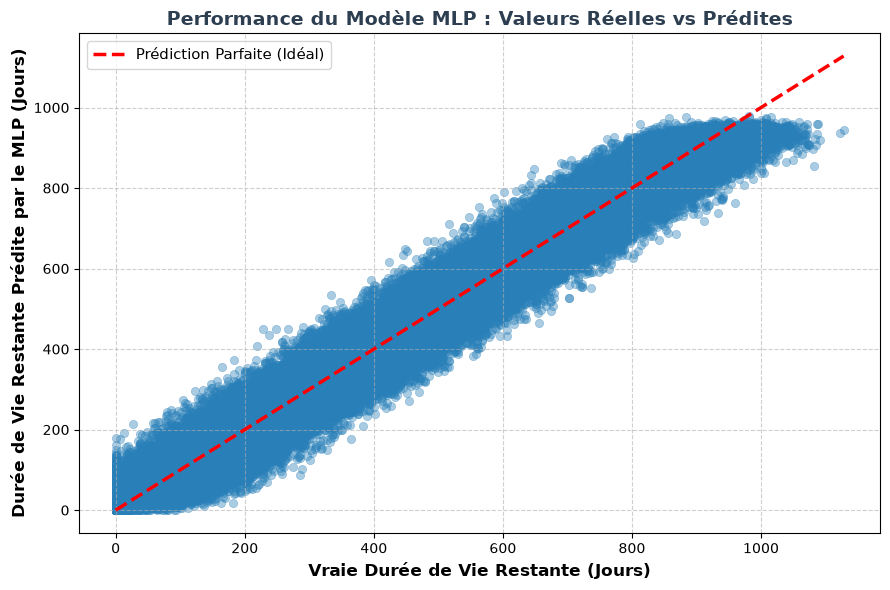

In [18]:
# === CELLULE POUR TRACER LE GRAPHIQUE VRAIS VS PRÉDITS ===
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

# Nuage de points des prédictions du modèle par rapport à la réalité
sns.scatterplot(x=y_te, y=test_preds, alpha=0.4, color='#2980B9', edgecolor=None)

# Ligne diagonale représentant une prédiction parfaite (y = x)
plt.min = min(y_te.min(), test_preds.min())
plt.max = max(y_te.max(), test_preds.max())
plt.plot([plt.min, plt.max], [plt.min, plt.max], 'r--', lw=2.5, label="Prédiction Parfaite (Idéal)")

plt.xlabel("Vraie Durée de Vie Restante (Jours)", fontsize=12, fontweight='bold')
plt.ylabel("Durée de Vie Restante Prédite par le MLP (Jours)", fontsize=12, fontweight='bold')
plt.title("Performance du Modèle MLP : Valeurs Réelles vs Prédites", fontsize=14, fontweight='bold', color='#2C3E50')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()